In [1]:
import xarray as xr
import matplotlib.pyplot as plt
import numpy as np 

#my own classes
import sys
sys.path.append("/emmy-noether/home/mf671/github/blocktrack/lib")
import blocktoolbox as BT

/home/links/mf671/miniconda3/envs/falwa_env/lib/python3.12/site-packages/pyproj/network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)


In [28]:
ds = xr.open_dataset('/home/links/mf671/DATA/ERA5/falwa_data/dw_lwa_daily_1980-1990.nc')
#print(ds['pfull'])
ds = ds.sel(latitude=slice(0, 90))
ds = ds.rename({'valid_time': 'time'})
ds = ds.rename({'latitude': 'lat'})
ds = ds.rename({'longitude': 'lon'})


In [29]:
ds

<xarray.Dataset>
Dimensions:  (time: 3804, lon: 240, lat: 61)
Coordinates:
  * time     (time) datetime64[ns] 1980-01-01T12:00:00 ... 1990-05-31T12:00:00
  * lon      (lon) float64 0.0 1.5 3.0 4.5 6.0 ... 352.5 354.0 355.5 357.0 358.5
  * lat      (lat) float64 0.0 1.5 3.0 4.5 6.0 7.5 ... 84.0 85.5 87.0 88.5 90.0
Data variables:
    dw_lwa   (time, lat, lon) float64 ...
Attributes:
    CDI:          Climate Data Interface version 1.9.7 (http://mpimet.mpg.de/...
    Conventions:  CF-1.6
    history:      Mon Aug 18 16:55:03 2025: cdo -selvar,dw_lwa -mergetime fal...
    CDO:          Climate Data Operators version 1.9.7 (http://mpimet.mpg.de/...

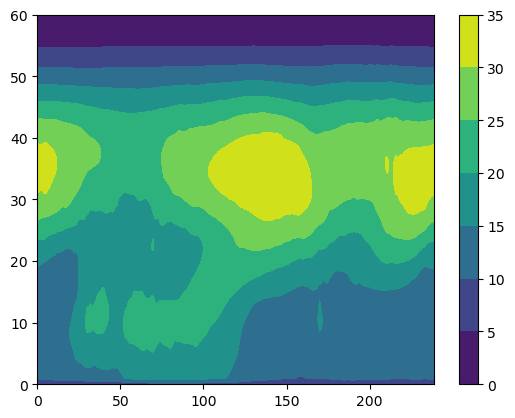

In [30]:
#levels = np.arange(0,0.2,0.01)
plt.contourf(ds['dw_lwa'].mean('time'))#,levels=np.arange(0,3,0.1))
#print(ds['dw_lwa'].loc[:,40:80,:].values.std())
plt.colorbar()

In [34]:
work_dir='/home/links/mf671/DATA/ERA5/falwa_data/'
fn_out_unfilt = work_dir + "falwa_LWAA_tracked_unfilt_1.5x1.5_daily_1980-1990.nc"
fn_out = work_dir + "falwa_LWAA_tracked_1.5x1.5_daily_1980-1990.nc"
fn_dic_unfilt = work_dir + "dictionaries/falwa_LWAA_tracked_unfilt_1.5x1.5_daily_1980-1990_DIC.npy"
fn_dic = work_dir + "dictionaries/falwa_LWAA_tracked_1.5x1.5_daily_1980-1990_DIC.npy" 

In [32]:
ds = BT.LWAA(ds,multiplicative_threshold = 1.26,lwa_name='dw_lwa')
ds,dic_unfilt = BT.ContourTracking2D(ds,var_name = "LWAA",geop_name='dw_lwa',overlap=0.5,grid=1.5)

__Starting a LWA anomaly process__
input: zg500 , multiplicative threshold = 1.26
(3804, 61, 240)
ref_std automatically computed


100%|█████████████████████████████████████████████████████████████████| 3714/3714 [00:01<00:00, 2673.99it/s]


__Starting a Tracking process__
input: LWAA
connected component analysis


100%|██████████████████████████████████████████████████████████████████| 3804/3804 [00:07<00:00, 475.67it/s]


rearranging indexes


100%|██████████████████████████████████████████████████████████████████| 3804/3804 [00:08<00:00, 441.34it/s]


calculating characteristics
persistence, track, date:


100%|███████████████████████████████████████████████████████████████████| 3804/3804 [00:49<00:00, 76.84it/s]


area, WBI and intensity


100%|███████████████████████████████████████████████████████████████████| 3804/3804 [07:17<00:00,  8.69it/s]


number of labels: 25328.0


In [35]:
ds.to_netcdf(fn_out_unfilt)
np.save(fn_dic_unfilt,dic_unfilt)

In [36]:
ds_filt,dic_filt = BT.FilterEvents(ds,dic_unfilt,var_name = "LWAA",pers_min = 5,min_avg_area = 3e5)
print("ContourTracking2D function correclty executed")
#saving data
np.save(fn_dic,dic_filt)
ds_filt.to_netcdf(fn_out)
print("Data created")

__Starting a Filtering process__
input: LWAA_tracked
applying filters


100%|██████████████████████████████████████████████████████████████| 25328/25328 [00:00<00:00, 37006.58it/s]


rearranging indexes


100%|████████████████████████████████████████████████████████████████| 3804/3804 [00:00<00:00, 11163.81it/s]


number of labels: 141
ContourTracking2D function correclty executed
Data created


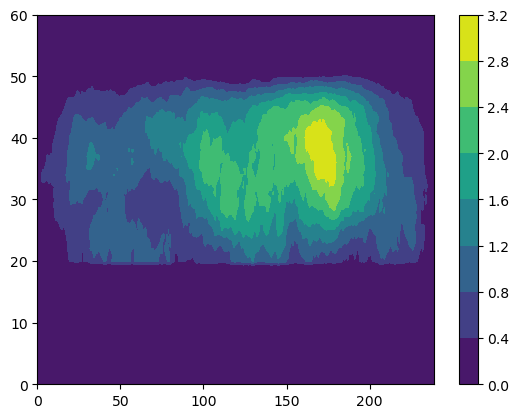

In [38]:
plt.contourf(ds_filt['LWAA_freq'])
plt.colorbar()